In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

In [3]:
keras.utils.set_random_seed(42) ### same random star every run, so results are repeatable

PROJECT_ROOT= Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "val.csv")

##label must be numbers too: negative=0, neutral =1 , posititve =2

LABELS = ["negative","neutral", "positive"]
label_to_id = {label: i for i, label in enumerate(LABELS)}
y_train = train_df["label"].map(label_to_id).to_numpy()
y_val = val_df["label"].map(label_to_id).to_numpy()

train_texts = train_df["sentence_clean"].tolist()
val_texts = val_df["sentence_clean"].tolist()
print("Train:",len(train_texts), "| Val:", len(val_texts))
print("First 5 labels as numbers:", y_train[:5])

Train: 2456 | Val: 492
First 5 labels as numbers: [1 2 2 2 2]


In [4]:
MAX_LEN = 50 

vectorizer = keras.layers.TextVectorization(
    max_tokens = 10000,   ###keep at most 10,00 diff words
    output_sequence_length = MAX_LEN, ##pad or cut every sentence to 50
    standardize = "lower",  ##lowercase only
    split = "whitespace" ##our text is already split by spces

)

vectorizer.adapt(train_texts)  ##learn the word list from train only

vocab = vectorizer.get_vocabulary()
print("Word learned:",len(vocab))
print("First 10 IDs:", vocab[:10])

X_train = vectorizer(train_texts).numpy()
X_val = vectorizer(val_texts).numpy()
print("\nX_train shape:",X_train.shape)
print("\nSentence:", train_texts[0])
print("As IDs:",X_train[0])

Word learned: 7698
First 10 IDs: ['', '[UNK]', np.str_('the'), np.str_('.'), np.str_(','), np.str_('of'), np.str_('in'), np.str_('and'), np.str_('to'), np.str_('million')]

X_train shape: (2456, 50)

Sentence: According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .
As IDs: [ 109    8 2810    4    2   16   29  204  671    8  398  147  119    8
  161    4 2156   36   15  381    2   16   15  865    3    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


In [5]:
from sklearn.utils.class_weight import compute_class_weight

VOCAB_SIZE = len(vocab)
weights = compute_class_weight("balanced",classes=np.array([0,1,2]),y=y_train)
class_weight = dict(enumerate(weights))
print("Class weights:", {LABELS[i]: round(w,2) for i,w in class_weight.items()})

model = keras.Sequential( [
    keras.Input(shape=(MAX_LEN,)),
    keras.layers.Embedding(input_dim=VOCAB_SIZE, output_dim=64, mask_zero=True), ##mask_zero: ignore the empty seats
    keras.layers.SimpleRNN(64),
    keras.layers.Dropout(0.3),   ##randomly switch off 30% during practise, so it can't memorize
    keras.layers.Dense(3, activation="softmax"), ##3 prob that up to 1
])
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Class weights: {'negative': np.float64(2.74), 'neutral': np.float64(0.54), 'positive': np.float64(1.3)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │       492,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 501,123 (1.91 MB)

 Trainable params: 501,123 (1.91 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs = 30,
    batch_size=32,
    class_weight= class_weight,
    callbacks= [early_stop],
    verbose=2,
)


Epoch 1/30
77/77 - 3s - 44ms/step - accuracy: 0.5314 - loss: 1.0063 - val_accuracy: 0.6911 - val_loss: 0.7487
Epoch 2/30
77/77 - 1s - 14ms/step - accuracy: 0.8050 - loss: 0.6356 - val_accuracy: 0.7561 - val_loss: 0.6243
Epoch 3/30
77/77 - 1s - 13ms/step - accuracy: 0.9418 - loss: 0.2684 - val_accuracy: 0.7175 - val_loss: 0.6861
Epoch 4/30
77/77 - 1s - 12ms/step - accuracy: 0.9813 - loss: 0.1048 - val_accuracy: 0.7053 - val_loss: 0.7897
Epoch 5/30
77/77 - 1s - 14ms/step - accuracy: 0.9923 - loss: 0.0619 - val_accuracy: 0.7419 - val_loss: 0.7804


In [8]:
from sklearn.metrics import f1_score, classification_report

val_pred = model.predict(X_val, verbose=0).argmax(axis=1)   # pick the class with the biggest probability
print("Val Macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 3))
print(classification_report(y_val, val_pred, target_names=LABELS, digits=3))

Val Macro-F1: 0.632
              precision    recall  f1-score   support

    negative      0.478     0.533     0.504        60
     neutral      0.830     0.941     0.882       306
    positive      0.667     0.413     0.510       126

    accuracy                          0.756       492
   macro avg      0.658     0.629     0.632       492
weighted avg      0.745     0.756     0.741       492



In [9]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(MAX_LEN,)),
    keras.layers.Embedding(input_dim=VOCAB_SIZE,output_dim=32, mask_zero=True),
    keras.layers.SimpleRNN(32),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(3, activation="softmax"),
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

early_stop= keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,restore_best_weights=True)

history= model.fit(X_train,y_train, validation_data=(X_val,y_val),epochs=30,batch_size=32,class_weight=class_weight,callbacks=[early_stop],verbose=2)

val_pred = model.predict(X_val).argmax(axis=1)
print("Val Macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 3))
print(classification_report(y_val, val_pred, target_names=LABELS, digits=3))

Epoch 1/30
77/77 - 3s - 36ms/step - accuracy: 0.4157 - loss: 1.0928 - val_accuracy: 0.4878 - val_loss: 1.0588
Epoch 2/30
77/77 - 1s - 9ms/step - accuracy: 0.6621 - loss: 0.9405 - val_accuracy: 0.6768 - val_loss: 0.8522
Epoch 3/30
77/77 - 1s - 9ms/step - accuracy: 0.8058 - loss: 0.7120 - val_accuracy: 0.6504 - val_loss: 0.8303
Epoch 4/30
77/77 - 1s - 10ms/step - accuracy: 0.9059 - loss: 0.4627 - val_accuracy: 0.6667 - val_loss: 0.8183
Epoch 5/30
77/77 - 1s - 9ms/step - accuracy: 0.9536 - loss: 0.2824 - val_accuracy: 0.6524 - val_loss: 0.8871
Epoch 6/30
77/77 - 1s - 9ms/step - accuracy: 0.9748 - loss: 0.1897 - val_accuracy: 0.6667 - val_loss: 0.8254
Epoch 7/30
77/77 - 1s - 9ms/step - accuracy: 0.9857 - loss: 0.1233 - val_accuracy: 0.7033 - val_loss: 0.8004
Epoch 8/30
77/77 - 1s - 12ms/step - accuracy: 0.9955 - loss: 0.0780 - val_accuracy: 0.7012 - val_loss: 0.8581
Epoch 9/30
77/77 - 1s - 10ms/step - accuracy: 0.9963 - loss: 0.0582 - val_accuracy: 0.7012 - val_loss: 0.8708
Epoch 10/30
77/

Epoch 1/30
77/77 - 4s - 47ms/step - accuracy: 0.5314 - loss: 1.0063 - val_accuracy: 0.6911 - val_loss: 0.7487
Epoch 2/30
77/77 - 1s - 13ms/step - accuracy: 0.8050 - loss: 0.6356 - val_accuracy: 0.7561 - val_loss: 0.6243
Epoch 3/30
77/77 - 1s - 12ms/step - accuracy: 0.9418 - loss: 0.2684 - val_accuracy: 0.7175 - val_loss: 0.6861
Epoch 4/30
77/77 - 1s - 16ms/step - accuracy: 0.9813 - loss: 0.1048 - val_accuracy: 0.7053 - val_loss: 0.7897
Epoch 5/30
77/77 - 1s - 13ms/step - accuracy: 0.9923 - loss: 0.0619 - val_accuracy: 0.7419 - val_loss: 0.7804
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
Val Macro-F1 (should be near 0.632): 0.632
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


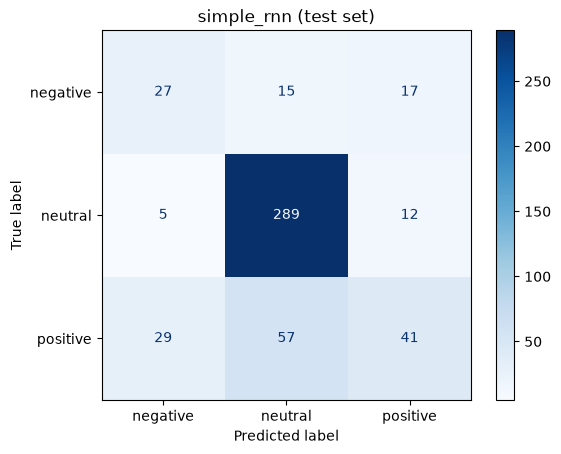

simple_rnn on test: accuracy 0.7256 | Macro-F1 0.5776
              precision    recall  f1-score   support

    negative      0.443     0.458     0.450        59
     neutral      0.801     0.944     0.867       306
    positive      0.586     0.323     0.416       127

    accuracy                          0.726       492
   macro avg      0.610     0.575     0.578       492
weighted avg      0.702     0.726     0.700       492

Saved model.


In [10]:
import sys, importlib
sys.path.append(str(PROJECT_ROOT))
import src.evaluate as ev
importlib.reload(ev)

# 1. Rebuild the FROZEN version 1 (64 units, dropout 0.3, normal learning rate)
keras.utils.set_random_seed(42)
model = keras.Sequential([
    keras.Input(shape=(MAX_LEN,)),
    keras.layers.Embedding(input_dim=VOCAB_SIZE, output_dim=64, mask_zero=True),
    keras.layers.SimpleRNN(64),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(3, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
model.fit(X_train, y_train, validation_data=(X_val, y_val),
          epochs=30, batch_size=32, class_weight=class_weight,
          callbacks=[early_stop], verbose=2)

val_pred = model.predict(X_val).argmax(axis=1)
print("Val Macro-F1 (should be near 0.632):", round(f1_score(y_val, val_pred, average="macro"), 3))

# 2. Load the TEST set and turn it into numbers with the SAME vectorizer
test_df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "test.csv")
X_test = vectorizer(test_df["sentence_clean"].tolist()).numpy()

# 3. Predict, turn ids (0,1,2) back into words, and score ONCE
test_pred_ids = model.predict(X_test).argmax(axis=1)
test_pred = [LABELS[i] for i in test_pred_ids]
metrics = ev.evaluate(test_df["label"].tolist(), test_pred, "simple_rnn", PROJECT_ROOT / "results")

# 4. Save the model
model.save(PROJECT_ROOT / "models" / "simple_rnn.keras")
print("Saved model.")